In [1]:
import pandas as pd

input_file_traj = "../input/em_trajectories.csv"
input_file_prices = "../input/prices.csv"

bat = "f2fa4e93-8507-42c1-b44d-576242a9f453"
evcs = "ef96659d-8317-4d5e-bec5-ac65a0628535"
pv = "294640d2-6fcf-4d96-a9e9-e988cba7c8cd"
load = "f368082d-1ede-4472-a71c-f2fadfaaa713"
# associated ev: 2bb84106-4144-4c0a-8b4a-bf5d02124d5c

opt_resolution = 3600
sim_resolution = 900
horizon = 86400

In [2]:
def create_table_cumulative(df: pd.DataFrame, uuid: str):
    df_cum = df[(df.asset_uuid == uuid) & (df.tick == df.current_tick + opt_resolution)].reset_index()
    df_cum = df_cum[["asset_uuid", "current_tick", "state", "e_min", "e_max"]]
    # add simulation resolution, since the cumulative sum below determines state at the end of each step
    df_cum.loc[:, "current_tick"] += sim_resolution
    df_cum.loc[:, ["state", "e_min", "e_max"]] *= sim_resolution/opt_resolution
    df_cum.loc[:, ["state", "e_min", "e_max"]] = df_cum.loc[:, ["state", "e_min", "e_max"]].cumsum()

    df_cum.index += 1
    df_cum.loc[0] = { "asset_uuid": uuid, "current_tick": 0, "state": 0.0, "e_min": 0.0, "e_max": 0.0 }
    df_cum.sort_index(inplace=True)

    # skip row because we added sim_resolution to last entry above
    return df_cum[:-1]

def create_table_absolute(df: pd.DataFrame, uuid: str):
    last_tick: int = df.current_tick.max()

    df_abs = df[(df.asset_uuid == uuid) & (df.tick == df.current_tick)]
    df_abs = df_abs[["asset_uuid", "current_tick", "state", "e_min", "e_max"]]

    # add missing values, if present
    fill_value = {"asset_uuid": uuid, "state": 0.0, "e_min": 0.0, "e_max": 0.0}
    new_index = pd.Index(range(0,last_tick+1,sim_resolution), name="current_tick")
    df_abs = df_abs.set_index("current_tick").reindex(new_index).reset_index().fillna(fill_value)

    return df_abs

In [3]:
def adapt_stateless_trajectories(df: pd.DataFrame, uuids: list[str]):
    df = df.copy()
    for adapt_uuid in uuids:
        current_ticks = df.current_tick.unique()

        last_diff = 0
        for current_tick in current_ticks:
            selection = (df.asset_uuid == adapt_uuid) & (df.current_tick == current_tick)
            df.loc[selection, "state"] += last_diff
            df.loc[selection, "e_min"] += last_diff
            df.loc[selection, "e_max"] += last_diff
            df.loc[selection, "tight_e_min"] += last_diff
            df.loc[selection, "tight_e_max"] += last_diff

            last_diff += (df[selection]["state"].iloc[1] - df[selection]["state"].iloc[0]) * sim_resolution/opt_resolution

    return df

In [4]:
def fill_disconnected(df: pd.DataFrame, uuids: list[str], fill_value):
    for adapt_uuid in uuids:
        current_ticks = df.current_tick.unique()

        add_rows = []
        for current_tick in current_ticks:
            selection = (df.asset_uuid == adapt_uuid) & (df.current_tick == current_tick)
            last_tick = df[selection]["tick"].max()

            # add filler values for missing ticks right after the last value
            if last_tick < current_tick + horizon:
                add_rows.append({"asset_uuid": adapt_uuid, "current_tick": current_tick, "tick": last_tick + opt_resolution, "state": fill_value, "e_min": fill_value, "e_max": fill_value, "tight_e_min": fill_value, "tight_e_max": fill_value})

        df = pd.concat([df, pd.DataFrame(add_rows)])

    return df

In [5]:
# load and prepare data

# TRAJECTORIES
traj_csv = pd.read_csv(input_file_traj)

# remove entries for last tick, because simona sets them to 0
max_tick = traj_csv.current_tick.max()
traj_csv.drop(traj_csv.index[traj_csv.current_tick == max_tick], inplace=True)

# realized boundaries and state trajectory
traj_real = pd.concat([
    create_table_cumulative(traj_csv, pv),
    create_table_cumulative(traj_csv, load),
    create_table_absolute(traj_csv, bat),
    create_table_absolute(traj_csv, evcs)
    ])

# adapt stateless trajectories (because they start at 0 at every simulated tick)
traj_full = adapt_stateless_trajectories(traj_csv, [pv, load])

# fill in disconnected ticks with 0
traj_full = fill_disconnected(traj_full, [evcs], 0.0) # optional: float('nan')

# PRICES
prices = pd.read_csv(input_file_prices)
prices['time'] = pd.to_datetime(prices['time'], format='%Y-%m-%dT%H:%M:%SZ')

prices['time'] = (prices['time'] - prices.loc[0, 'time']).map(lambda s: s.total_seconds())

In [6]:
import matplotlib.pyplot as plt

def plot_trajectory2(traj):
    curr_ticks = traj.current_tick.unique()

    plt.subplots(figsize=(20, 6))

    plt.xticks(range(0, 72*3600+1, 3600*4))

    for curr_tick in curr_ticks:
        state_tick = traj[traj.current_tick == curr_tick]

        if curr_tick % sim_resolution == 0:
            color="black"
        else:
            color="gray"
        plt.plot(state_tick["tick"], state_tick["e_min"], c="blue")
        plt.plot(state_tick["tick"], state_tick["e_max"], c="green")
        plt.plot(state_tick["tick"], state_tick["state"], c=color)

    state_realized = traj[traj.current_tick == traj.tick]
    plt.plot(state_realized["tick"], state_realized["state"], c="red")

    plt.show()

def plot_trajectory(traj, traj_sim):
    plt.subplots(figsize=(20, 6))
    plt.xticks(range(0, 72*3600+1, 3600*4))

    curr_ticks = traj.current_tick.unique()
    for curr_tick in curr_ticks:
        state_tick = traj[traj.current_tick == curr_tick]

        plt.plot(state_tick["tick"], state_tick["tight_e_min"], c="#b8b6fc66")
        plt.plot(state_tick["tick"], state_tick["tight_e_max"], c="#00800466")

        plt.plot(state_tick["tick"], state_tick["state"], c="black")

    plt.plot(traj_sim["current_tick"], traj_sim["e_min"], c="pink")
    plt.plot(traj_sim["current_tick"], traj_sim["e_max"], c="pink")
    plt.plot(traj_sim["current_tick"], traj_sim["state"], c="red")

    plt.show()

def plot_prices(prices):
    plt.subplots(figsize=(20, 6))

    plt.xticks(range(0, 72*3600+1, 3600*4))

    plt.plot(prices["time"], prices["price"])
    plt.show()


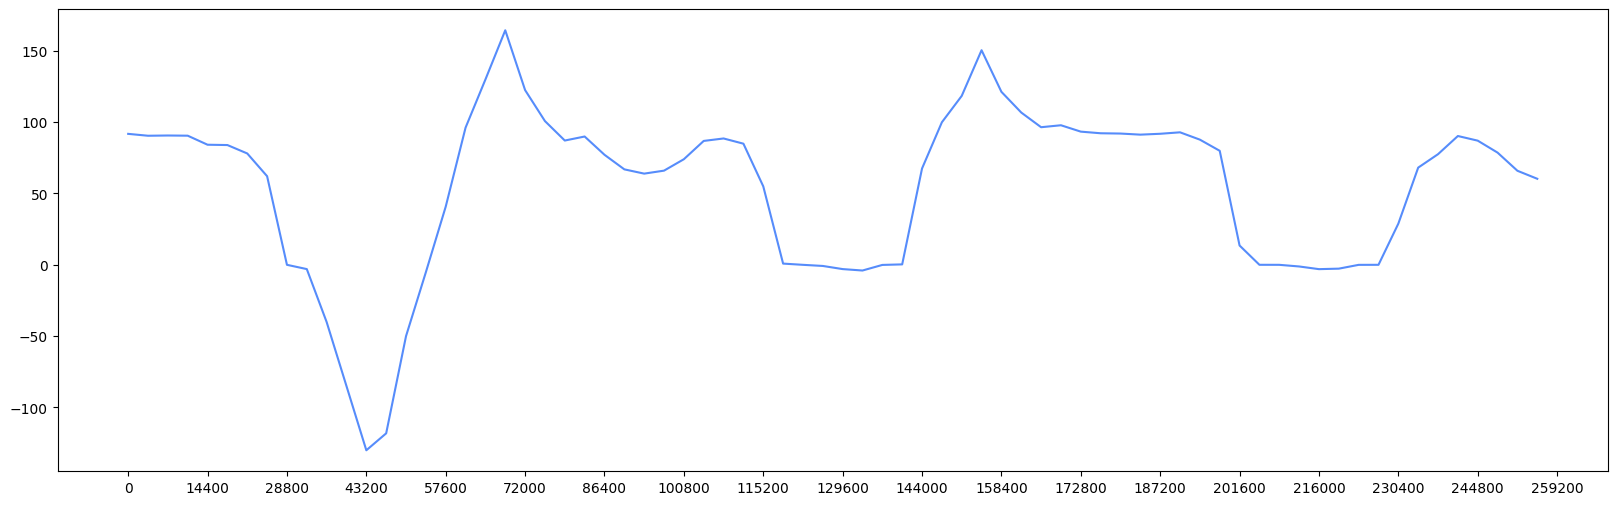

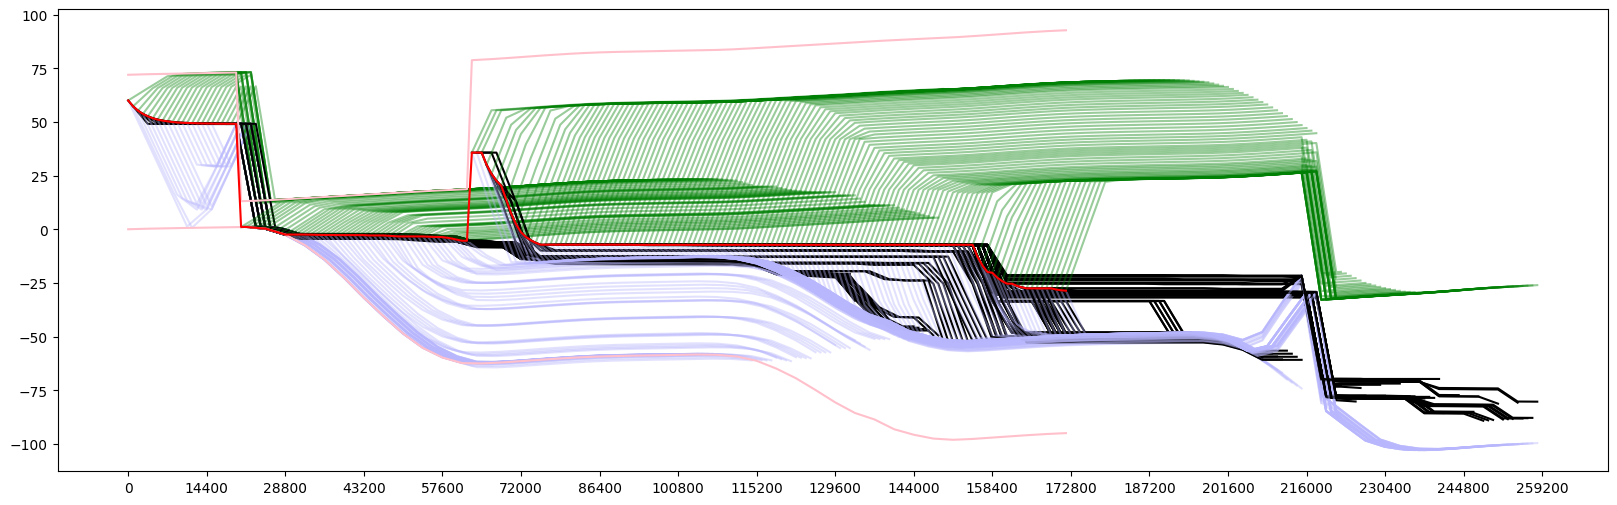

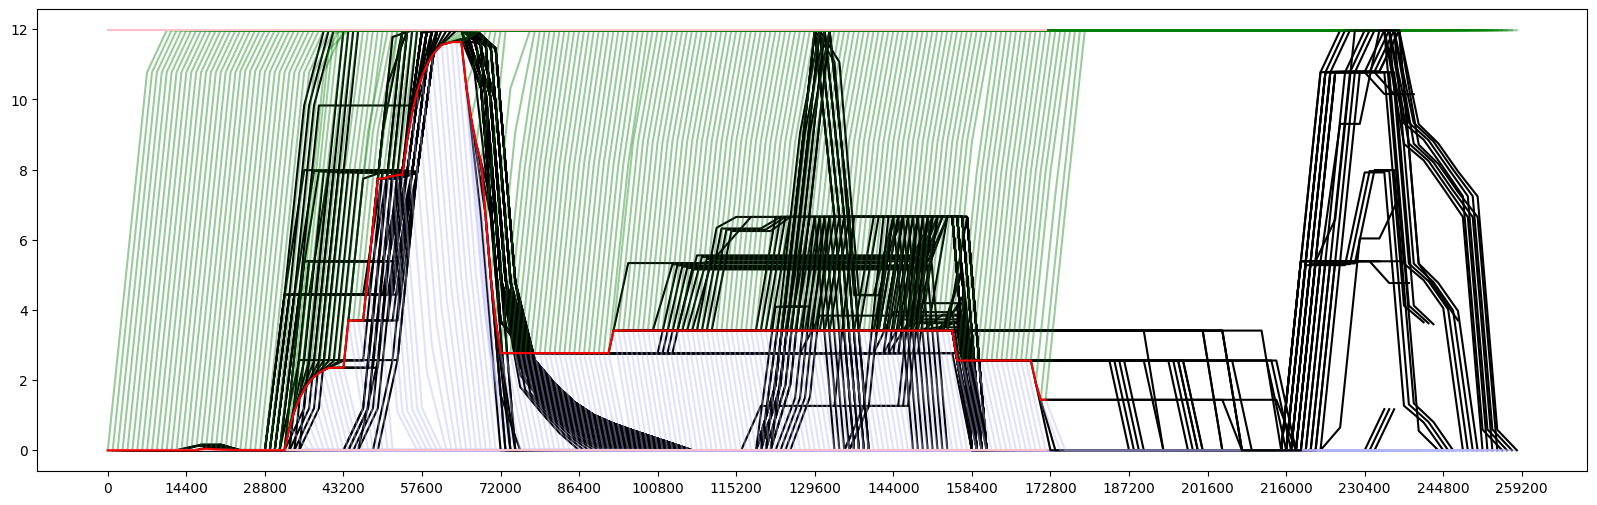

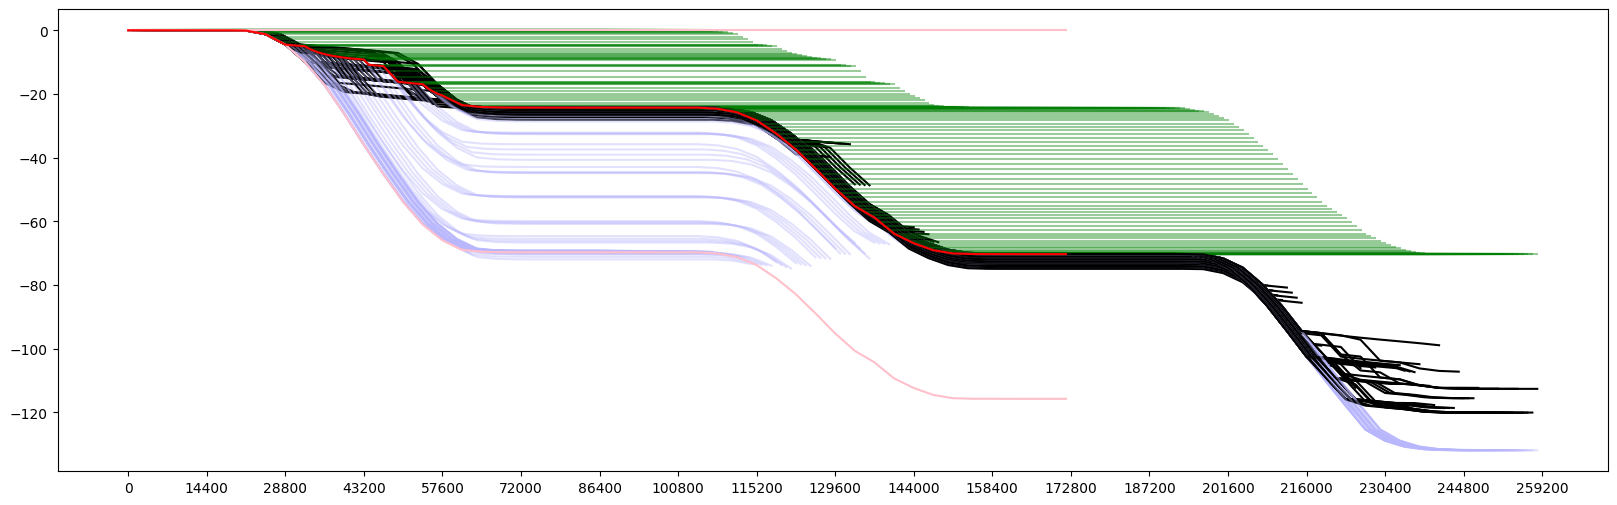

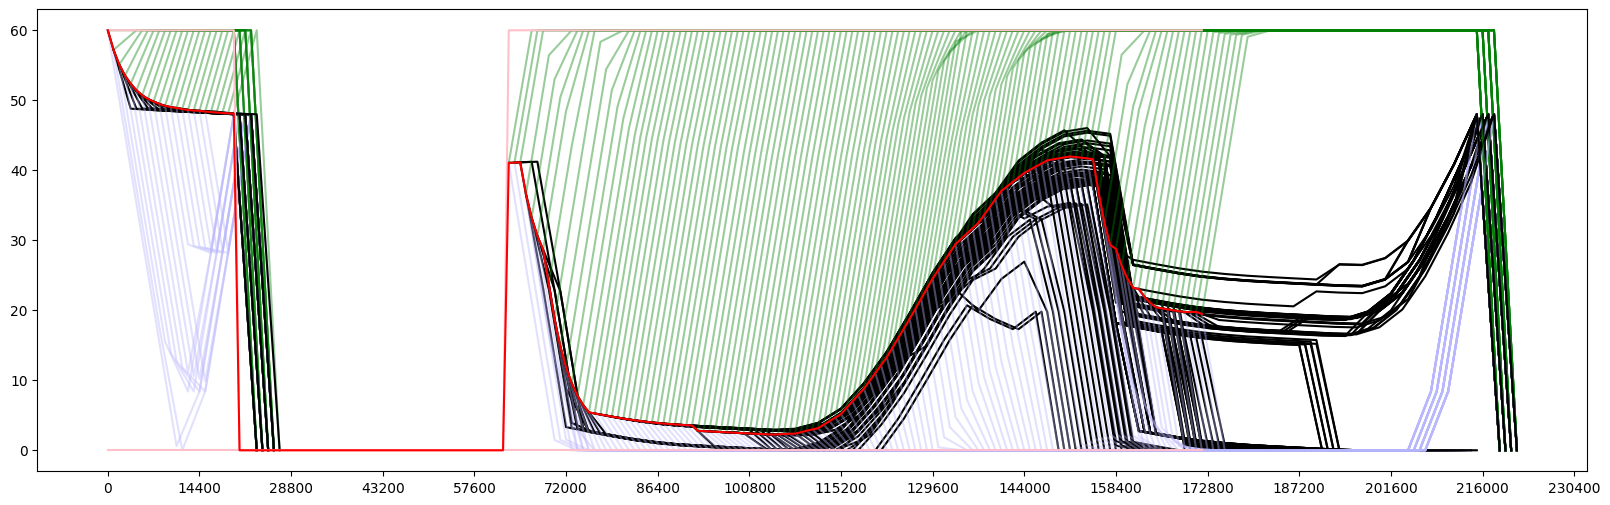

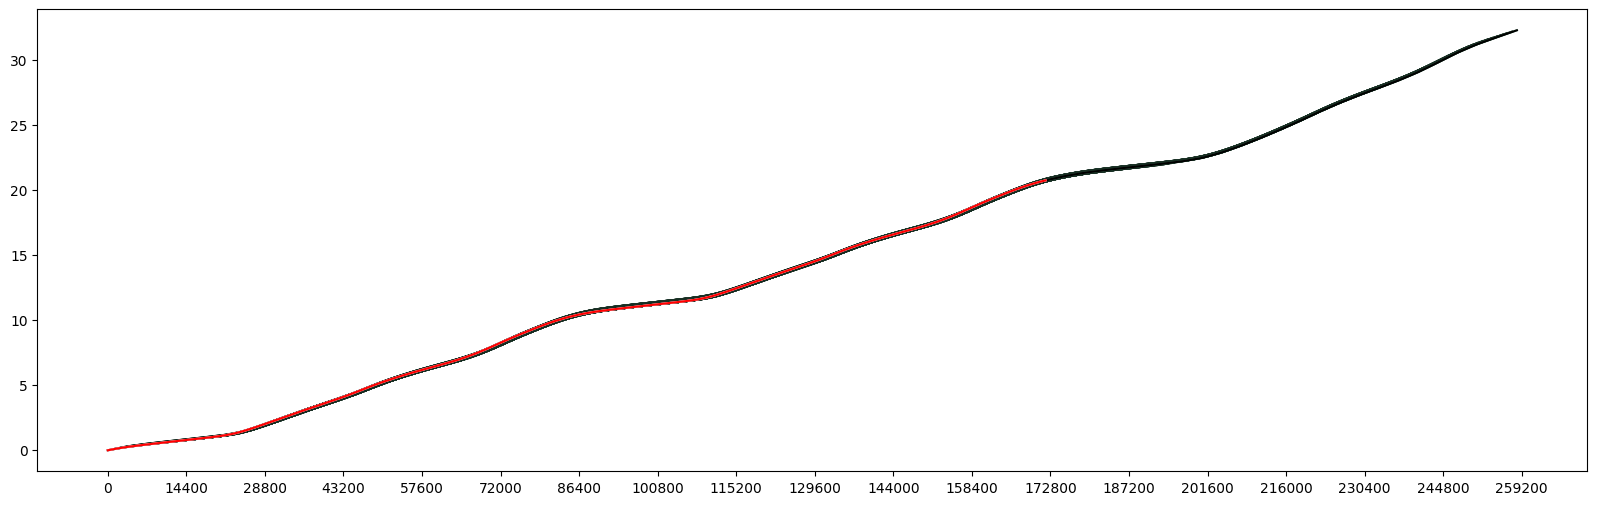

In [7]:
# PLOTTING
# prices
plot_prices(prices)

# summed
traj_full_sum = traj_full.groupby(["current_tick", "tick"], as_index=False)[["state", "e_min", "e_max", "tight_e_min", "tight_e_max"]].sum()
traj_real_sum = traj_real.groupby("current_tick", as_index=False)[["state", "e_min", "e_max"]].sum()
plot_trajectory(traj_full_sum, traj_real_sum)

# single
plot_trajectory(traj_full[traj_full.asset_uuid == bat], traj_real[traj_real.asset_uuid == bat])
plot_trajectory(traj_full[traj_full.asset_uuid == pv], traj_real[traj_real.asset_uuid == pv])
plot_trajectory(traj_full[traj_full.asset_uuid == evcs], traj_real[traj_real.asset_uuid == evcs])
plot_trajectory(traj_full[traj_full.asset_uuid == load], traj_real[traj_real.asset_uuid == load])


In [ ]:
from pathlib import Path

# Output

out_dir = "traj_out"
Path(out_dir).mkdir(exist_ok=True)

assets = traj_full.asset_uuid.unique()

for asset in assets:
    asset_traj = traj_full[traj_full.asset_uuid == asset]

    curr_ticks = asset_traj.current_tick.unique()
    for curr_tick in curr_ticks: #[0, 900, 1800, 2700, 3600]:
        asset_tick_traj = asset_traj[asset_traj.current_tick == curr_tick]

        file_name = "traj_" + asset + "_" + str(curr_tick) + ".csv"
        asset_tick_traj.to_csv(out_dir + "/" + file_name, columns=["tick", "state", "tight_e_min", "tight_e_max"], index=False)

